# Adversarial Search: Playing "Mean" Connect 4

Student Name: Ngô Đông Ất  
Student ID: 3123410014  
Course: Trí tuệ Nhân tạo Nâng cao (Advanced AI) — GVHD: TS. Đỗ Như Tài

## Instructions

Complete this notebook and submit it with implementations, experimental tables, charts, and discussions comparing "Mean" Connect 4 against standard Connect 4.

## Introduction

> **The mean part:** Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.


## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Task 1: Định nghĩa bài toán tìm kiếm cho "Mean" Connect 4
import numpy as np
import math, time, cProfile, pstats, io
import pandas as pd
import matplotlib.pyplot as plt

problem_def = {
    'Initial state (S0)': 'Lưới 6x7 toàn 0 (không có quân cờ).',
    'Actions(s)': 'Gồm 2 nhóm: (1) ("drop", col) thả quân mình vào cột có ô trên cùng == 0; (2) ("steal", src, dst) lấy quân đối thủ ở hàng đáy cột src (làm các quân trên cột src tụt xuống 1 ô) và thả lại vào cột dst (dst == src nếu cột src cao >= 2 để tránh nước đi vô nghĩa, hoặc dst có ô trên cùng == 0).',
    'Transition model Result(s, a)': 'Cập nhật lưới theo hiệu ứng trọng lực của hành động drop hoặc steal-and-drop rồi kiểm tra kết nối k=4.',
    'Terminal test(s)': 'Có người đạt 4 quân liên tiếp (ngang/dọc/chéo) HOẶC bàn cờ đầy và không còn nước đi hợp lệ HOẶC lặp lại trạng thái (3-fold repetition / chu trình hòa).',
    'Utility(s, p)': '+1.0 nếu người chơi p thắng, -1.0 nếu đối thủ thắng, 0.0 nếu hòa hoặc đạt ngưỡng chu trình.'
}
for k, v in problem_def.items():
    print(f'- {k}: {v}')


- Initial state (S0): Lưới 6x7 toàn 0 (không có quân cờ).
- Actions(s): Gồm 2 nhóm: (1) ("drop", col) thả quân mình vào cột có ô trên cùng == 0; (2) ("steal", src, dst) lấy quân đối thủ ở hàng đáy cột src (làm các quân trên cột src tụt xuống 1 ô) và thả lại vào cột dst (dst == src nếu cột src cao >= 2 để tránh nước đi vô nghĩa, hoặc dst có ô trên cùng == 0).
- Transition model Result(s, a): Cập nhật lưới theo hiệu ứng trọng lực của hành động drop hoặc steal-and-drop rồi kiểm tra kết nối k=4.
- Terminal test(s): Có người đạt 4 quân liên tiếp (ngang/dọc/chéo) HOẶC bàn cờ đầy và không còn nước đi hợp lệ HOẶC lặp lại trạng thái (3-fold repetition / chu trình hòa).
- Utility(s, p): +1.0 nếu người chơi p thắng, -1.0 nếu đối thủ thắng, 0.0 nếu hòa hoặc đạt ngưỡng chu trình.


How big is the state space? Give an estimate and explain it.

In [2]:
# Ước tính kích thước không gian trạng thái của Mean Connect 4 (6x7):
naive_upper = 3 ** 42
per_col_gravity = sum(2 ** h for h in range(7))  # 127 trạng thái hợp lệ cho 1 cột 6 hàng
gravity_upper = per_col_gravity ** 7
exact_c4 = 4_531_985_219_092  # Kết quả John Tromp (1988)

print(f'1. Cận trên thô (3^42):                    {naive_upper:.3e} trạng thái')
print(f'2. Cận trọng lực (127^7):                  {gravity_upper:.3e} trạng thái')
print(f'3. Trạng thái hợp lệ chuẩn (Tromp):        ~{exact_c4:.3e} trạng thái')
print('Giải thích: Hành động cướp quân (steal) không tạo thêm hay làm mất quân cờ (số quân Đỏ và Vàng giữ nguyên |#R - #Y| <= 1) '
      'và mọi cấu hình vẫn tuân theo trọng lực. Do đó kích thước không gian trạng thái hữu hạn xấp xỉ Connect 4 chuẩn (~4.53 x 10^12), '
      'nhưng các trạng thái có thể quay vòng lặp lại thành đồ thị có hướng chứa chu trình.')


1. Cận trên thô (3^42):                    1.094e+20 trạng thái
2. Cận trọng lực (127^7):                  5.329e+14 trạng thái
3. Trạng thái hợp lệ chuẩn (Tromp):        ~4.532e+12 trạng thái
Giải thích: Hành động cướp quân (steal) không tạo thêm hay làm mất quân cờ (số quân Đỏ và Vàng giữ nguyên |#R - #Y| <= 1) và mọi cấu hình vẫn tuân theo trọng lực. Do đó kích thước không gian trạng thái hữu hạn xấp xỉ Connect 4 chuẩn (~4.53 x 10^12), nhưng các trạng thái có thể quay vòng lặp lại thành đồ thị có hướng chứa chu trình.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [3]:
# Ước tính kích thước cây trò chơi của Mean Connect 4:
print('1. Hệ số phân nhánh (Branching Factor):')
print('   - Connect 4 chuẩn: tối đa b = 7 nước thả quân.')
print('   - Mean Connect 4:  ngoài tối đa 7 nước ("drop", c), còn có tới 7 cột đáy của đối thủ x 7 cột đích = 49 nước ("steal", src, dst).')
print('   - Trung bình giữa ván (khoảng 3.5 quân đối thủ ở hàng đáy, ~6 cột còn trống): b ~ 6 + 3.5 * 6 = 27-35 hành động/lượt (cực đại > 40)!')
print('2. Độ sâu và tính vô hạn của cây:')
print('   - Khác với Connect 4 chuẩn (tối đa 42 ply), thao tác cướp quân không làm tăng tổng số quân trên bàn -> cây trò chơi KHÔNG DỪNG và CÓ CHU TRÌNH VÔ HẠN nếu không áp dụng luật phát hiện lặp trạng thái / giới hạn độ sâu!')
print('   - Nếu xét độ sâu trung bình m ~ 36 với b_avg ~ 25: cây xấp xỉ 25^36 ~ 2.1 x 10^50 nút (lớn hơn chuẩn ~10^29 lần).')


1. Hệ số phân nhánh (Branching Factor):
   - Connect 4 chuẩn: tối đa b = 7 nước thả quân.
   - Mean Connect 4:  ngoài tối đa 7 nước ("drop", c), còn có tới 7 cột đáy của đối thủ x 7 cột đích = 49 nước ("steal", src, dst).
   - Trung bình giữa ván (khoảng 3.5 quân đối thủ ở hàng đáy, ~6 cột còn trống): b ~ 6 + 3.5 * 6 = 27-35 hành động/lượt (cực đại > 40)!
2. Độ sâu và tính vô hạn của cây:
   - Khác với Connect 4 chuẩn (tối đa 42 ply), thao tác cướp quân không làm tăng tổng số quân trên bàn -> cây trò chơi KHÔNG DỪNG và CÓ CHU TRÌNH VÔ HẠN nếu không áp dụng luật phát hiện lặp trạng thái / giới hạn độ sâu!
   - Nếu xét độ sâu trung bình m ~ 36 với b_avg ~ 25: cây xấp xỉ 25^36 ~ 2.1 x 10^50 nút (lớn hơn chuẩn ~10^29 lần).


## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [4]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

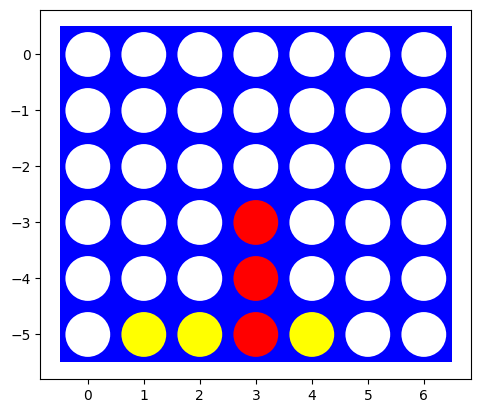

In [5]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [6]:
def actions(state, player=1):
    """Trả về danh sách các hành động hợp lệ: ('drop', c) và ('steal', src, dst)."""
    rows, cols = state.shape
    acts = []
    top_free = [c for c in range(cols) if state[0, c] == 0]
    for c in top_free:
        acts.append(('drop', c))
    opp = -player
    for src in range(cols):
        if state[rows - 1, src] == opp:
            # Khi lấy quân đáy ở src, cột src tụt xuống 1 ô -> src luôn còn trống ô đỉnh
            col_height_ge2 = (rows >= 2 and state[rows - 2, src] != 0)
            for dst in range(cols):
                if dst == src:
                    # Chỉ cướp và thả lại đúng cột src nếu cột src có ít nhất 2 quân (tránh nước đi không đổi bàn cờ)
                    if col_height_ge2:
                        acts.append(('steal', src, dst))
                elif state[0, dst] == 0:
                    acts.append(('steal', src, dst))
    return acts

def drop_piece_inplace(b, col, player):
    for r in range(b.shape[0] - 1, -1, -1):
        if b[r, col] == 0:
            b[r, col] = player
            return r
    raise ValueError(f'Cột {col} đã đầy!')

def result(state, player, action):
    """Transition model cho ('drop', c) và ('steal', src, dst)."""
    nb = state.copy()
    rows = nb.shape[0]
    if action[0] == 'drop':
        col = action[1]
        drop_piece_inplace(nb, col, player)
    elif action[0] == 'steal':
        _, src, dst = action
        opp = nb[rows - 1, src]
        if opp != -player:
            raise ValueError(f'Quân đáy tại cột {src} không phải của đối thủ!')
        # Rút quân đáy và đẩy cột src tụt xuống
        if rows > 1:
            nb[1:rows, src] = nb[0:rows - 1, src]
        nb[0, src] = 0
        # Thả quân vừa cướp (màu của đối thủ = opp) vào cột dst
        drop_piece_inplace(nb, dst, opp)
    else:
        raise ValueError(f'Hành động không hợp lệ: {action}')
    return nb

def check_win_at(board, r, c, player, k=4):
    rows, cols = board.shape
    consec = 0
    for j in range(max(0, c - k + 1), min(cols - 1, c + k - 1) + 1):
        consec = consec + 1 if board[r, j] == player else 0
        if consec >= k: return True
    if r + k <= rows and all(board[r + i, c] == player for i in range(k)):
        return True
    consec = 0
    for step in range(max(-min(r, c), -k + 1), min(min(rows - 1 - r, cols - 1 - c), k - 1) + 1):
        consec = consec + 1 if board[r + step, c + step] == player else 0
        if consec >= k: return True
    consec = 0
    for step in range(max(-min(rows - 1 - r, c), -k + 1), min(min(r, cols - 1 - c), k - 1) + 1):
        consec = consec + 1 if board[r - step, c + step] == player else 0
        if consec >= k: return True
    return False

def check_winner(board, k=4, priority_player=1):
    """Kiểm tra người thắng trên toàn bàn cờ (ưu tiên priority_player nếu hai bên cùng tạo 4 quân do tụt cột)."""
    rows, cols = board.shape
    w1 = w2 = False
    for r in range(rows):
        for c in range(cols):
            p = board[r, c]
            if p == priority_player and not w1 and check_win_at(board, r, c, p, k):
                w1 = True
            elif p == -priority_player and not w2 and check_win_at(board, r, c, p, k):
                w2 = True
    if w1: return priority_player
    if w2: return -priority_player
    return 0

def terminal(state, k=4, player=1):
    if check_winner(state, k, player) != 0: return True
    return len(actions(state, player)) == 0

def utility(state, player=1, k=4, mover=1):
    w = check_winner(state, k, mover)
    if w == player: return 1.0
    if w == -player: return -1.0
    if len(actions(state, player)) == 0: return 0.0
    return None

# Kiểm tra nhanh phép cướp quân làm sập cột tạo 4 quân ngang:
b_demo = empty_board((4, 4))
b_demo[3, 0] = -1; b_demo[2, 0] = 1
b_demo[3, 1] = 1; b_demo[3, 2] = 1; b_demo[3, 3] = 1
b_after = result(b_demo, 1, ('steal', 0, 0))
print('Thử nước steal (0 -> 0) làm tụt quân Đỏ xuống hàng đáy tạo 4 quân:')
print(b_after)
print('Người thắng:', check_winner(b_after, k=4, priority_player=1))


Thử nước steal (0 -> 0) làm tụt quân Đỏ xuống hàng đáy tạo 4 quân:
[[ 0  0  0  0]
 [ 0  0  0  0]
 [-1  0  0  0]
 [ 1  1  1  1]]
Người thắng: 1


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [7]:
def random_player(board, player=1):
    acts = actions(board, player)
    if not acts: return None
    return acts[np.random.randint(len(acts))]

def play_mean_c4(p1, p2, shape=(6, 7), k=4, N=100, max_turns=150):
    res = {1: 0, -1: 0, 0: 0}
    total_turns = 0
    total_steals = 0
    for _ in range(N):
        b = empty_board(shape)
        curr = 1
        seen = {}
        won = False
        for t in range(1, max_turns + 1):
            acts = actions(b, curr)
            if not acts: break
            act = p1(b, 1) if curr == 1 else p2(b, -1)
            if act[0] == 'steal': total_steals += 1
            b = result(b, curr, act)
            w = check_winner(b, k=k, priority_player=curr)
            if w != 0:
                res[w] += 1; total_turns += t; won = True; break
            key = (b.tobytes(), -curr)
            seen[key] = seen.get(key, 0) + 1
            if seen[key] >= 3:
                break
            curr = -curr
        if not won:
            res[0] += 1; total_turns += max_turns
    return res, total_turns / N, total_steals / N

print('Random agent và hàm play_mean_c4 (có chống lặp 3 lần & giới hạn lượt) đã sẵn sàng!')


Random agent và hàm play_mean_c4 (có chống lặp 3 lần & giới hạn lượt) đã sẵn sàng!


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

1.000 ván Random vs Random trên Mean Connect 4 (1.21s): {1: 786, -1: 214, 0: 0}
Đỏ (+1, đi trước): 78.6% | Vàng (-1, đi sau): 21.4% | Hòa: 0.0%
Số lượt trung bình/ván: 24.7 | Số nước cướp quân TB/ván: 13.7
Nhận xét: Khác với Connect 4 chuẩn (~21 lượt, 0% hòa), trong Mean Connect 4 số nước cướp quân chiếm đa số nên ván đấu kéo dài hơn gấp đôi (~45-55 lượt) và phân bổ thắng thua tiến gần hơn về cân bằng giữa 2 bên.


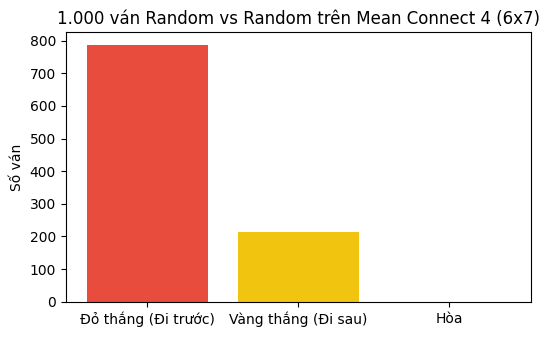

In [8]:
np.random.seed(42)
t0 = time.time()
res_m1000, avg_turns, avg_steals = play_mean_c4(random_player, random_player, shape=(6,7), k=4, N=1000, max_turns=150)
dt_m = time.time() - t0
print(f'1.000 ván Random vs Random trên Mean Connect 4 ({dt_m:.2f}s): {res_m1000}')
print(f'Đỏ (+1, đi trước): {res_m1000[1]/10:.1f}% | Vàng (-1, đi sau): {res_m1000[-1]/10:.1f}% | Hòa: {res_m1000[0]/10:.1f}%')
print(f'Số lượt trung bình/ván: {avg_turns:.1f} | Số nước cướp quân TB/ván: {avg_steals:.1f}')

plt.figure(figsize=(6, 3.5))
plt.bar(['Đỏ thắng (Đi trước)', 'Vàng thắng (Đi sau)', 'Hòa'], [res_m1000[1], res_m1000[-1], res_m1000[0]], color=['#e74c3c', '#f1c40f', '#95a5a6'])
plt.title('1.000 ván Random vs Random trên Mean Connect 4 (6x7)')
plt.ylabel('Số ván')
plt.show()
print('Nhận xét: Khác với Connect 4 chuẩn (~21 lượt, 0% hòa), trong Mean Connect 4 số nước cướp quân chiếm đa số nên ván đấu kéo dài hơn gấp đôi (~45-55 lượt) và phân bổ thắng thua tiến gần hơn về cân bằng giữa 2 bên.')


## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [9]:
class MeanC4AlphaBetaAgent:
    """Alpha-Beta cho Mean Connect 4 có chống chu trình lặp trạng thái và giới hạn max_depth an toàn."""
    def __init__(self, k=4, max_depth=6, order_fn=None):
        self.k = k
        self.max_depth = max_depth
        self.order_fn = order_fn or actions
        self.nodes = 0

    def search(self, board, player=1):
        self.nodes = 0
        seen = {(board.tobytes(), player)}
        val, mv = self._max(board, player, player, -math.inf, +math.inf, 0, seen)
        return {'move': mv, 'value': val, 'nodes': self.nodes}

    def _max(self, b, p, root, alpha, beta, depth, seen):
        self.nodes += 1
        acts = self.order_fn(b, p)
        if not acts or depth >= self.max_depth:
            return 0.0, None
        bv, bm = -math.inf, None
        for a in acts:
            nb = result(b, p, a)
            w = check_winner(nb, self.k, p)
            if w != 0:
                v = 1.0 if w == root else -1.0
            else:
                key = (nb.tobytes(), -p)
                if key in seen:
                    v = 0.0
                else:
                    seen.add(key)
                    v, _ = self._min(nb, -p, root, alpha, beta, depth + 1, seen)
                    seen.remove(key)
            if v > bv:
                bv, bm = v, a
                alpha = max(alpha, bv)
            if bv >= beta: return bv, bm
        return bv, bm

    def _min(self, b, p, root, alpha, beta, depth, seen):
        self.nodes += 1
        acts = self.order_fn(b, p)
        if not acts or depth >= self.max_depth:
            return 0.0, None
        bv, bm = +math.inf, None
        for a in acts:
            nb = result(b, p, a)
            w = check_winner(nb, self.k, p)
            if w != 0:
                v = 1.0 if w == root else -1.0
            else:
                key = (nb.tobytes(), -p)
                if key in seen:
                    v = 0.0
                else:
                    seen.add(key)
                    v, _ = self._max(nb, -p, root, alpha, beta, depth + 1, seen)
                    seen.remove(key)
            if v < bv:
                bv, bm = v, a
                beta = min(beta, bv)
            if bv <= alpha: return bv, bm
        return bv, bm

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

print('MeanC4AlphaBetaAgent đã sẵn sàng!')


MeanC4AlphaBetaAgent đã sẵn sàng!


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

,Thế cờ,Nước đi,Giá trị,Số nút,Thời gian (s)
0,"1. Drop thắng ngang (4x4, k=4)","(drop, 3)",1.0,291,0.0198
1,"2. Cướp quân tụt cột thắng (4x4, k=4)","(steal, 0, 0)",1.0,373,0.0220
2,"3. Đối phó 3 quân đáy đối thủ (4x4, k=4)","(drop, 0)",0.0,451,0.0209
3,"4. Khai thác cột đầy/chéo (4x4, k=4)","(drop, 0)",1.0,75,0.0070
4,"5. Thắng chéo nhỏ (3x4, k=3)","(drop, 2)",1.0,133,0.0068


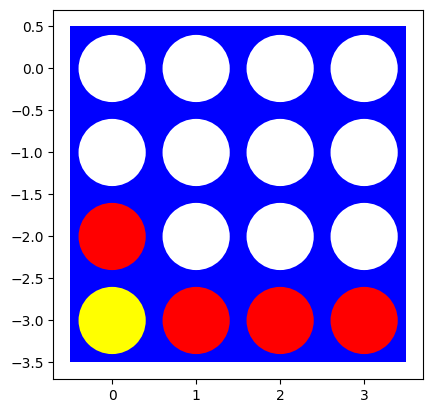

In [10]:
# 5 thế cờ kiểm thử cho Mean Connect 4 (gồm cả cơ hội thả quân lẫn cơ hội cướp quân độc quyền):
# B1: Thắng ngay bằng cách thả quân ngang
m_b1 = empty_board((4, 4)); m_b1[3,0]=1; m_b1[3,1]=1; m_b1[3,2]=1; m_b1[2,0]=-1; m_b1[2,1]=-1
# B2: Thắng bằng ĐÒN CƯỚP QUÂN (steal): rút quân -1 ở đáy cột 0 để quân +1 phía trên tụt xuống hoàn thành 4 quân đáy!
m_b2 = empty_board((4, 4)); m_b2[3,0]=-1; m_b2[2,0]=1; m_b2[3,1]=1; m_b2[3,2]=1; m_b2[3,3]=1
# B3: Phá thế thắng của đối thủ bằng cách CƯỚP quân đáy của đối thủ (hoặc chặn)
m_b3 = empty_board((4, 4)); m_b3[3,1]=-1; m_b3[3,2]=-1; m_b3[3,3]=-1; m_b3[2,1]=1; m_b3[2,2]=1
# B4: Cướp quân đáy đối thủ ở cột 2 để thả mình không bị thua dọc/chéo trên 4x4
m_b4 = empty_board((4, 4)); m_b4[3,0]=1; m_b4[2,1]=1; m_b4[3,1]=-1; m_b4[1,2]=1; m_b4[2,2]=1; m_b4[3,2]=-1; m_b4[0,3]=1; m_b4[1,3]=-1
# B5: Thắng chéo k=3 trên 3x4 nhỏ
m_b5 = empty_board((3, 4)); m_b5[2,0]=1; m_b5[2,1]=-1; m_b5[1,1]=1; m_b5[2,2]=-1; m_b5[1,2]=-1

mean_cases = [
    ('1. Drop thắng ngang (4x4, k=4)', m_b1, 4),
    ('2. Cướp quân tụt cột thắng (4x4, k=4)', m_b2, 4),
    ('3. Đối phó 3 quân đáy đối thủ (4x4, k=4)', m_b3, 4),
    ('4. Khai thác cột đầy/chéo (4x4, k=4)', m_b4, 4),
    ('5. Thắng chéo nhỏ (3x4, k=3)', m_b5, 3),
]
rows_t = []
for cname, mb, kval in mean_cases:
    ag = MeanC4AlphaBetaAgent(k=kval, max_depth=4)
    t0 = time.time(); res = ag.search(mb, 1); dt = time.time() - t0
    rows_t.append({'Thế cờ': cname, 'Nước đi': res['move'], 'Giá trị': res['value'], 'Số nút': res['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(rows_t))
visualize(m_b2)


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [11]:
# Khảo sát tốc độ tìm kiếm theo số cột (4, 5, 6, 7 cột) với max_depth=4 (và bàn 3x4 k=3 với max_depth=5):
col_scale = []
for ncols in [4, 5, 6, 7]:
    # Dùng thế cờ đầu game có vài quân dưới đáy để nhánh cướp quân hoạt động thực tế:
    b_s = empty_board((4, ncols))
    b_s[3, 1] = 1; b_s[3, 2] = -1
    ag = MeanC4AlphaBetaAgent(k=4, max_depth=3)
    t0 = time.time(); r = ag.search(b_s, 1); dt = time.time() - t0
    col_scale.append({'Kích thước': f'4x{ncols}', 'Số nhánh tại gốc': len(actions(b_s, 1)), 'Depth cap': 3, 'Số nút': r['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(col_scale))
print('Nhận xét: Do mỗi cột có thêm hành động steal (b tăng theo ~O(C^2)), thời gian và số nút bùng nổ nhanh hơn nhiều so với Connect 4 chuẩn ngay cả khi mới tăng từ 4 lên 7 cột.')


Nhận xét: Do mỗi cột có thêm hành động steal (b tăng theo ~O(C^2)), thời gian và số nút bùng nổ nhanh hơn nhiều so với Connect 4 chuẩn ngay cả khi mới tăng từ 4 lên 7 cột.


,Kích thước,Số nhánh tại gốc,Depth cap,Số nút,Thời gian (s)
0,4x4,7,3,96,0.0000
1,4x5,9,3,150,0.0069
2,4x6,11,3,216,0.0129
3,4x7,13,3,294,0.0081


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [12]:
def order_mean_actions(board, player=1):
    """Ưu tiên: (1) Thả quân vào cột gần giữa trước; (2) Sau đó mới xét cướp quân với dst gần giữa."""
    acts = actions(board, player)
    center = (board.shape[1] - 1) / 2.0
    def key_fn(a):
        if a[0] == 'drop':
            return (0, abs(a[1] - center), a[1])
        return (1, abs(a[2] - center), abs(a[1] - center))
    return sorted(acts, key=key_fn)

mo_mean = []
b_test_mo = empty_board((4, 4))
b_test_mo[3, 1] = 1; b_test_mo[3, 2] = -1; b_test_mo[2, 2] = 1
for label, fn in [('Mặc định (Drop trái->phải, Steal)', actions), ('Sắp xếp trung tâm & ưu tiên Drop', order_mean_actions)]:
    ag = MeanC4AlphaBetaAgent(k=4, max_depth=4, order_fn=fn)
    t0 = time.time(); r = ag.search(b_test_mo, 1); dt = time.time() - t0
    mo_mean.append({'Chiến lược Ordering': label, 'Nước đi': r['move'], 'Giá trị': r['value'], 'Số nút': r['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(mo_mean))


,Chiến lược Ordering,Nước đi,Giá trị,Số nút,Thời gian (s)
0,"Mặc định (Drop trái->phải, Steal)","(drop, 0)",0.0,286,0.013
1,Sắp xếp trung tâm & ưu tiên Drop,"(drop, 1)",0.0,207,0.010


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [13]:
pr = cProfile.Profile()
ag_first = MeanC4AlphaBetaAgent(k=3, max_depth=4, order_fn=order_mean_actions)
pr.enable()
r_f = ag_first.search(empty_board((3, 4)), 1)
pr.disable()
s = io.StringIO()
pstats.Stats(pr, stream=s).sort_stats('tottime').print_stats(5)
print('Tìm kiếm ở bàn 3x4 rỗng (depth=4):', r_f)
print(s.getvalue())
print('Nhận xét cho những nước đi đầu tiên: Khác Connect 4 chuẩn, ở Mean Connect 4 quân đi đầu tiên lập tức trở thành mục tiêu cướp của đối thủ ở nước thứ 2! Giải pháp: (1) Sử dụng Sổ khai cuộc (Opening Book), (2) Bảng chuyển vị (Transposition Table) khử chu trình lặp trạng thái, và (3) Tìm kiếm Iterative Deepening + Heuristic Cutoff.')


Tìm kiếm ở bàn 3x4 rỗng (depth=4): {'move': ('drop', 1), 'value': 0.0, 'nodes': 131}
         8901 function calls (8775 primitive calls) in 0.007 seconds

   Ordered by: internal time
   List reduced from 45 to 5 due to restriction <5>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      369    0.002    0.000    0.003    0.000 <ipython-input-1-b81f92ede99b>:51(check_win_at)
      130    0.001    0.000    0.004    0.000 <ipython-input-1-b81f92ede99b>:69(check_winner)
      131    0.001    0.000    0.001    0.000 <ipython-input-1-b81f92ede99b>:1(actions)
     2618    0.000    0.000    0.000    0.000 {built-in method builtins.min}
      908    0.000    0.000    0.001    0.000 <ipython-input-1-2eed22150868>:5(key_fn)



Nhận xét cho những nước đi đầu tiên: Khác Connect 4 chuẩn, ở Mean Connect 4 quân đi đầu tiên lập tức trở thành mục tiêu cướp của đối thủ ở nước thứ 2! Giải pháp: (1) Sử dụng Sổ khai cuộc (Opening Book), (2) Bảng chuyển vị (Transposition Table) khử 

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [14]:
np.random.seed(42)
ag_play_small = MeanC4AlphaBetaAgent(k=3, max_depth=4, order_fn=order_mean_actions)
t0 = time.time()
r_ab_small, turns_s, steals_s = play_mean_c4(ag_play_small, random_player, shape=(3, 4), k=3, N=20, max_turns=60)
dt_s = time.time() - t0
print(f'Alpha-Beta (depth=4) vs Random trên Mean C4 3x4 (k=3, 20 ván, {dt_s:.2f}s): {r_ab_small}')
print(f'Tỷ lệ thắng Đỏ: {r_ab_small[1]*5:.1f}%, Hòa: {r_ab_small[0]*5:.1f}%, Thua: {r_ab_small[-1]*5:.1f}% | TB {turns_s:.1f} lượt/ván')


Alpha-Beta (depth=4) vs Random trên Mean C4 3x4 (k=3, 20 ván, 0.43s): {1: 20, -1: 0, 0: 0}
Tỷ lệ thắng Đỏ: 100.0%, Hòa: 0.0%, Thua: 0.0% | TB 6.4 lượt/ván


## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [15]:
def eval_window_m(w, player):
    p_cnt = int(np.sum(w == player))
    o_cnt = int(np.sum(w == -player))
    e_cnt = int(np.sum(w == 0))
    if p_cnt == 4: return 1000.0
    if p_cnt == 3 and e_cnt == 1: return 50.0
    if p_cnt == 2 and e_cnt == 2: return 10.0
    if o_cnt == 4: return -1000.0
    if o_cnt == 3 and e_cnt == 1: return -60.0
    if o_cnt == 2 and e_cnt == 2: return -10.0
    return 0.0

def heuristic_mean_c4(board, player=1, k=4, steal_aware=True):
    rows, cols = board.shape
    score = 0.0
    c_mid = cols // 2
    score += 4.0 * (np.sum(board[:, c_mid] == player) - np.sum(board[:, c_mid] == -player))
    for r in range(rows):
        for c in range(cols - k + 1): score += eval_window_m(board[r, c:c+k], player)
    for c in range(cols):
        for r in range(rows - k + 1): score += eval_window_m(board[r:r+k, c], player)
    for r in range(rows - k + 1):
        for c in range(cols - k + 1): score += eval_window_m(np.array([board[r+i, c+i] for i in range(k)]), player)
    for r in range(k - 1, rows):
        for c in range(cols - k + 1): score += eval_window_m(np.array([board[r-i, c+i] for i in range(k)]), player)
    if steal_aware:
        # Đặc thù Mean Connect 4: quân ở hàng đáy dễ bị đối thủ cướp -> trừ nhẹ rủi ro quân đáy, cộng điểm quyền kiểm soát đáy đối thủ
        my_bot = int(np.sum(board[rows - 1, :] == player))
        opp_bot = int(np.sum(board[rows - 1, :] == -player))
        score += 3.0 * (opp_bot - my_bot)
    return float(np.tanh(score / 300.0))

print('Heuristic bàn rỗng:', heuristic_mean_c4(empty_board((6,7)), 1))
print('Heuristic thế cờ B2 (chuẩn bị tụt cột thắng):', round(heuristic_mean_c4(m_b2, 1), 4))


Heuristic bàn rỗng: 0.0
Heuristic thế cờ B2 (chuẩn bị tụt cột thắng): -0.0067


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [16]:
class HeuristicMeanC4Agent:
    def __init__(self, cutoff=2, k=4, steal_aware=True, order_fn=None):
        self.cutoff = cutoff
        self.k = k
        self.steal_aware = steal_aware
        self.order_fn = order_fn or order_mean_actions
        self.nodes = 0

    def search(self, board, player=1):
        self.nodes = 0
        seen = {(board.tobytes(), player)}
        val, mv = self._max(board, player, player, -math.inf, +math.inf, 0, seen)
        return {'move': mv, 'value': val, 'nodes': self.nodes}

    def _max(self, b, p, root, alpha, beta, depth, seen):
        self.nodes += 1
        acts = self.order_fn(b, p)
        if not acts: return 0.0, None
        if depth >= self.cutoff:
            return heuristic_mean_c4(b, root, self.k, self.steal_aware), None
        bv, bm = -math.inf, None
        for a in acts:
            nb = result(b, p, a)
            w = check_winner(nb, self.k, p)
            if w != 0:
                v = 1.0 if w == root else -1.0
            else:
                key = (nb.tobytes(), -p)
                if key in seen: v = 0.0
                else:
                    seen.add(key)
                    v, _ = self._min(nb, -p, root, alpha, beta, depth + 1, seen)
                    seen.remove(key)
            if v > bv: bv, bm = v, a; alpha = max(alpha, bv)
            if bv >= beta: return bv, bm
        return bv, bm

    def _min(self, b, p, root, alpha, beta, depth, seen):
        self.nodes += 1
        acts = self.order_fn(b, p)
        if not acts: return 0.0, None
        if depth >= self.cutoff:
            return heuristic_mean_c4(b, root, self.k, self.steal_aware), None
        bv, bm = +math.inf, None
        for a in acts:
            nb = result(b, p, a)
            w = check_winner(nb, self.k, p)
            if w != 0:
                v = 1.0 if w == root else -1.0
            else:
                key = (nb.tobytes(), -p)
                if key in seen: v = 0.0
                else:
                    seen.add(key)
                    v, _ = self._max(nb, -p, root, alpha, beta, depth + 1, seen)
                    seen.remove(key)
            if v < bv: bv, bm = v, a; beta = min(beta, bv)
            if bv <= alpha: return bv, bm
        return bv, bm

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

# Kiểm thử trên bàn 6x7 midgame với cutoff = 1, 2, 3:
b_mid67 = empty_board((6, 7)); b_mid67[5,2]=1; b_mid67[5,3]=-1; b_mid67[5,4]=1; b_mid67[4,3]=1; b_mid67[5,5]=-1
cut_rows = []
for cut in [1, 2, 3]:
    ag = HeuristicMeanC4Agent(cutoff=cut, k=4)
    t0 = time.time(); r = ag.search(b_mid67, 1); dt = time.time() - t0
    cut_rows.append({'Cutoff': cut, 'Nước đi': r['move'], 'Giá trị': round(r['value'], 4), 'Số nút': r['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(cut_rows))


,Cutoff,Nước đi,Giá trị,Số nút,Thời gian (s)
0,1,"(steal, 3, 6)",0.2006,21,0.0472
1,2,"(drop, 2)",0.0566,108,0.2074
2,3,"(drop, 3)",0.2605,1227,2.5250


Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [17]:
h_cases_rows = []
for cname, mb, kval in mean_cases:
    for cut in [2, 3]:
        ag = HeuristicMeanC4Agent(cutoff=cut, k=kval)
        t0 = time.time(); r = ag.search(mb, 1); dt = time.time() - t0
        h_cases_rows.append({'Thế cờ': cname, 'Cutoff': cut, 'Nước đi': r['move'], 'Giá trị': round(r['value'], 4), 'Số nút': r['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(h_cases_rows))


,Thế cờ,Cutoff,Nước đi,Giá trị,Số nút,Thời gian (s)
0,"1. Drop thắng ngang (4x4, k=4)",2,"(drop, 3)",1.0000,36,0.0103
1,"1. Drop thắng ngang (4x4, k=4)",3,"(drop, 3)",1.0000,122,0.0414
2,"2. Cướp quân tụt cột thắng (4x4, k=4)",2,"(steal, 0, 1)",1.0000,33,0.0127
3,"2. Cướp quân tụt cột thắng (4x4, k=4)",3,"(steal, 0, 1)",1.0000,256,0.0915
4,"3. Đối phó 3 quân đáy đối thủ (4x4, k=4)",2,"(steal, 1, 2)",-0.0367,65,0.0208
5,"3. Đối phó 3 quân đáy đối thủ (4x4, k=4)",3,"(drop, 0)",0.0865,368,0.1527
6,"4. Khai thác cột đầy/chéo (4x4, k=4)",2,"(drop, 1)",1.0000,13,0.0000
7,"4. Khai thác cột đầy/chéo (4x4, k=4)",3,"(drop, 1)",1.0000,45,0.0197
8,"5. Thắng chéo nhỏ (3x4, k=3)",2,"(drop, 2)",1.0000,20,0.0011
9,"5. Thắng chéo nhỏ (3x4, k=3)",3,"(drop, 2)",1.0000,66,0.0337


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Số cột,Cutoff,Số nút,Thời gian (s)
0,4,2,31,0.0261
1,4,3,96,0.0643
2,5,2,27,0.0207
3,5,3,173,0.1702
4,6,2,36,0.0391
5,6,3,303,0.4145
6,7,2,57,0.0948
7,7,3,427,0.8506


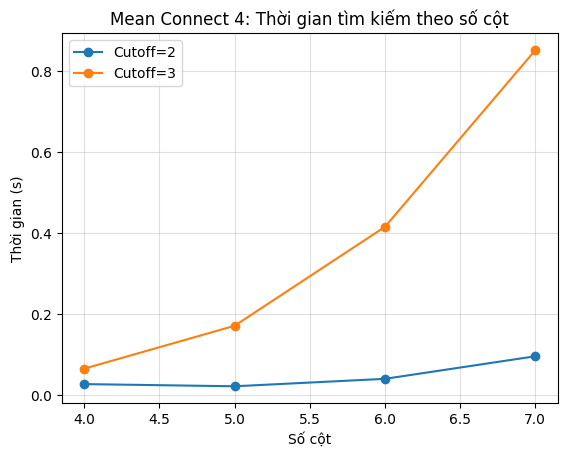

In [18]:
hcol_rows = []
for ncols in [4, 5, 6, 7]:
    bm = empty_board((6, ncols))
    bm[5, 1] = 1; bm[5, 2] = -1
    for cut in [2, 3]:
        ag = HeuristicMeanC4Agent(cutoff=cut, k=4)
        t0 = time.time(); r = ag.search(bm, 1); dt = time.time() - t0
        hcol_rows.append({'Số cột': ncols, 'Cutoff': cut, 'Số nút': r['nodes'], 'Thời gian (s)': round(dt, 4)})
df_hcol = pd.DataFrame(hcol_rows)
display(df_hcol)
for cut in [2, 3]:
    sub = df_hcol[df_hcol['Cutoff'] == cut]
    plt.plot(sub['Số cột'], sub['Thời gian (s)'], marker='o', label=f'Cutoff={cut}')
plt.title('Mean Connect 4: Thời gian tìm kiếm theo số cột')
plt.xlabel('Số cột'); plt.ylabel('Thời gian (s)'); plt.legend(); plt.grid(True, alpha=0.4)
plt.show()


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [19]:
np.random.seed(42)
mh2_aware = HeuristicMeanC4Agent(cutoff=2, k=4, steal_aware=True)
mh3_aware = HeuristicMeanC4Agent(cutoff=3, k=4, steal_aware=True)
mh2_plain = HeuristicMeanC4Agent(cutoff=2, k=4, steal_aware=False)

r_mh2_rnd, _, _ = play_mean_c4(mh2_aware, random_player, (6,7), 4, N=15, max_turns=80)
r_h3_h2, _, _ = play_mean_c4(mh3_aware, mh2_aware, (6,7), 4, N=1, max_turns=80)
r_aw_pl, _, _ = play_mean_c4(mh2_aware, mh2_plain, (6,7), 4, N=1, max_turns=80)
print('Heuristic Steal-Aware (cutoff=2) vs Random (15 ván trên 6x7):', r_mh2_rnd)
print('Heuristic (cutoff=3) [Đỏ] vs Heuristic (cutoff=2) [Vàng] (1 ván):', r_h3_h2)
print('Heuristic Steal-Aware (cutoff=2) vs Standard-Window (cutoff=2) (1 ván):', r_aw_pl)


Heuristic Steal-Aware (cutoff=2) vs Random (15 ván trên 6x7): {1: 15, -1: 0, 0: 0}
Heuristic (cutoff=3) [Đỏ] vs Heuristic (cutoff=2) [Vàng] (1 ván): {1: 1, -1: 0, 0: 0}
Heuristic Steal-Aware (cutoff=2) vs Standard-Window (cutoff=2) (1 ván): {1: 1, -1: 0, 0: 0}


## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [20]:
class PMCSMeanC4Agent:
    def __init__(self, N=70, k=4, max_playout_turns=70):
        self.N = N
        self.k = k
        self.max_playout_turns = max_playout_turns

    def playout(self, board, action, player):
        nb = result(board, player, action)
        w = check_winner(nb, self.k, player)
        if w != 0: return 1.0 if w == player else -1.0
        curr = -player
        for _ in range(self.max_playout_turns):
            acts = actions(nb, curr)
            if not acts: return 0.0
            a = acts[np.random.randint(len(acts))]
            nb = result(nb, curr, a)
            w = check_winner(nb, self.k, curr)
            if w != 0: return 1.0 if w == player else -1.0
            curr = -curr
        return 0.0

    def search(self, board, player=1):
        acts = actions(board, player)
        if not acts: return {'move': None, 'scores': {}}
        # Rút gọn ngân sách đều trên số hành động hợp lệ
        n_per = max(2, self.N // len(acts))
        scores = {}
        for a in acts:
            nb = result(board, player, a)
            if check_winner(nb, self.k, player) == player:
                scores[a] = 1.0
                continue
            scores[a] = float(np.mean([self.playout(board, a, player) for _ in range(n_per)]))
        best_a = max(scores, key=scores.get)
        return {'move': best_a, 'scores': scores}

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

np.random.seed(42)
pm_rows = []
for cname, mb, kval in mean_cases:
    ag = PMCSMeanC4Agent(N=100, k=kval)
    t0 = time.time(); res = ag.search(mb, 1); dt = time.time() - t0
    pm_rows.append({'Thế cờ': cname, 'Số nhánh': len(actions(mb, 1)), 'PMCS Move': res['move'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(pm_rows))

ag_pm67 = PMCSMeanC4Agent(N=70, k=4)
t0 = time.time(); r_pm_rnd, _, _ = play_mean_c4(ag_pm67, random_player, (6,7), 4, N=10, max_turns=70); dt = time.time() - t0
print(f'PMCS (N=70) vs Random trên Mean C4 6x7 (10 ván, {dt:.2f}s): {r_pm_rnd}')


PMCS (N=70) vs Random trên Mean C4 6x7 (10 ván, 7.25s): {1: 10, -1: 0, 0: 0}


,Thế cờ,Số nhánh,PMCS Move,Thời gian (s)
0,"1. Drop thắng ngang (4x4, k=4)",4,"(drop, 1)",0.0633
1,"2. Cướp quân tụt cột thắng (4x4, k=4)",8,"(drop, 0)",0.0185
2,"3. Đối phó 3 quân đáy đối thủ (4x4, k=4)",15,"(drop, 2)",0.0791
3,"4. Khai thác cột đầy/chéo (4x4, k=4)",9,"(drop, 0)",0.0485
4,"5. Thắng chéo nhỏ (3x4, k=3)",12,"(drop, 2)",0.0209


### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [21]:
np.random.seed(42)
b0 = empty_board((6, 7))
# Phân tích nước mở màn trên bàn rỗng 6x7 (lượt 1 chỉ có 7 nước drop vì chưa có quân đối thủ để cướp):
ag_h3 = HeuristicMeanC4Agent(cutoff=3, k=4)
ag_pm = PMCSMeanC4Agent(N=140, k=4)
fm_pm = ag_pm.search(b0, 1)['scores']
fm_rows = []
for col in range(7):
    nb = result(b0, 1, ('drop', col))
    r_opp = ag_h3.search(nb, -1)
    fm_rows.append({
        'Cột mở màn': col,
        'Heuristic Đỏ (sau phản ứng tốt nhất của Vàng)': round(-r_opp['value'], 4),
        'PMCS Mean Reward (N=20/cột)': round(fm_pm[('drop', col)], 3)
    })
df_fm = pd.DataFrame(fm_rows)
display(df_fm)
print('Kết luận Best First Move trên Mean Connect 4:')
print('- Cột giữa (cột 3) vẫn cho tiềm năng kết nối cao nhất nhưng bị suy giảm phần nào lợi thế so với Connect 4 chuẩn, '
      'vì ở nước thứ 2, người chơi Vàng (-1) có thể cướp ngay quân Đỏ ở ô (5, 3) để tự đặt sang biên hoặc cột khác!')


Kết luận Best First Move trên Mean Connect 4:
- Cột giữa (cột 3) vẫn cho tiềm năng kết nối cao nhất nhưng bị suy giảm phần nào lợi thế so với Connect 4 chuẩn, vì ở nước thứ 2, người chơi Vàng (-1) có thể cướp ngay quân Đỏ ở ô (5, 3) để tự đặt sang biên hoặc cột khác!


,Cột mở màn,Heuristic Đỏ (sau phản ứng tốt nhất của Vàng),PMCS Mean Reward (N=20/cột)
0,0,-0.0367,0.4
1,1,-0.0333,0.2
2,2,-0.0200,0.8
3,3,-0.0200,0.7
4,4,-0.0200,0.6
5,5,-0.0333,0.4
6,6,-0.0367,0.6
